<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/day4_visualisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick student-mat.csv

Saving student-mat.csv to student-mat.csv


{'student-mat.csv': b'school;sex;age;address;famsize;Pstatus;Medu;Fedu;Mjob;Fjob;reason;guardian;traveltime;studytime;failures;schoolsup;famsup;paid;activities;nursery;higher;internet;romantic;famrel;freetime;goout;Dalc;Walc;health;absences;G1;G2;G3\n"GP";"F";18;"U";"GT3";"A";4;4;"at_home";"teacher";"course";"mother";2;2;0;"yes";"no";"no";"no";"yes";"yes";"no";"no";4;3;4;1;1;3;6;"5";"6";6\n"GP";"F";17;"U";"GT3";"T";1;1;"at_home";"other";"course";"father";1;2;0;"no";"yes";"no";"no";"no";"yes";"yes";"no";5;3;3;1;1;3;4;"5";"5";6\n"GP";"F";15;"U";"LE3";"T";1;1;"at_home";"other";"other";"mother";1;2;3;"yes";"no";"yes";"no";"yes";"yes";"yes";"no";4;3;2;2;3;3;10;"7";"8";10\n"GP";"F";15;"U";"GT3";"T";4;2;"health";"services";"home";"mother";1;3;0;"no";"yes";"yes";"yes";"yes";"yes";"yes";"yes";3;2;2;1;1;5;2;"15";"14";15\n"GP";"F";16;"U";"GT3";"T";3;3;"other";"other";"home";"father";1;2;0;"no";"yes";"yes";"no";"yes";"yes";"no";"no";4;3;2;1;2;5;4;"6";"10";10\n"GP";"M";16;"U";"LE3";"T";4;3;"service

In [2]:
# Cell 1: setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("student-mat.csv", sep=";")
df.shape

(395, 33)

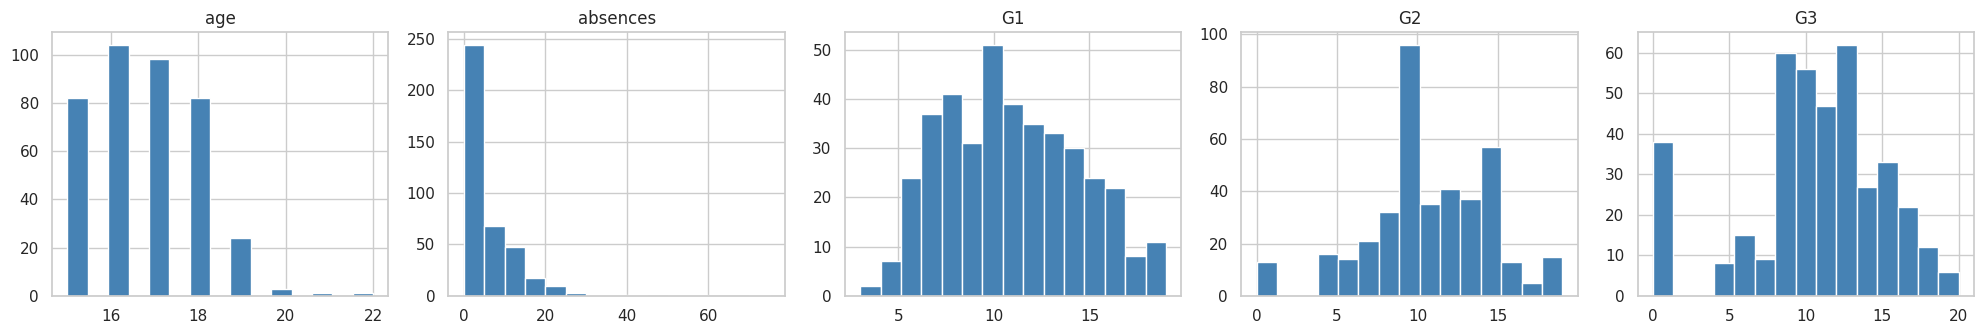

In [3]:
# Cell 2: histograms of key numeric columns
cols = ["age", "absences", "G1", "G2", "G3"]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, c in zip(axes, cols):
    ax.hist(df[c], bins=15, color="steelblue", edgecolor="white")
    ax.set_title(c)
plt.tight_layout()
plt.show()

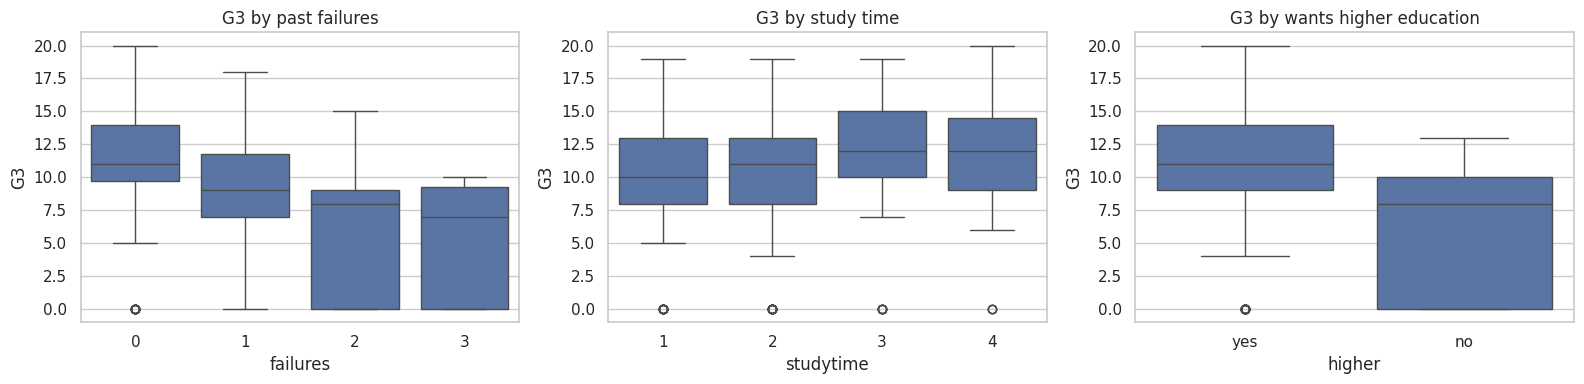

In [4]:
# Cell 3: box plots, G3 across groups
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(x="failures", y="G3", data=df, ax=axes[0])
sns.boxplot(x="studytime", y="G3", data=df, ax=axes[1])
sns.boxplot(x="higher", y="G3", data=df, ax=axes[2])
axes[0].set_title("G3 by past failures")
axes[1].set_title("G3 by study time")
axes[2].set_title("G3 by wants higher education")
plt.tight_layout()
plt.show()

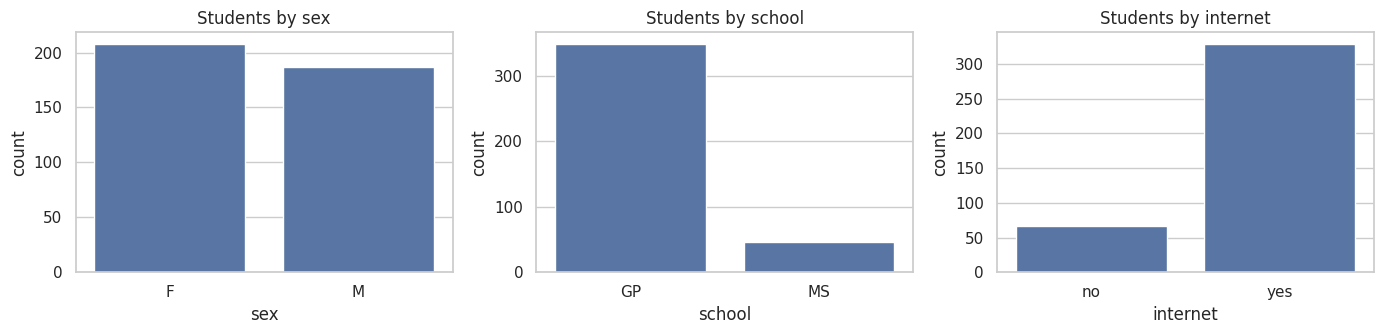

In [5]:
# Cell 4: category counts
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, ["sex", "school", "internet"]):
    sns.countplot(x=c, data=df, ax=ax)
    ax.set_title(f"Students by {c}")
plt.tight_layout()
plt.show()

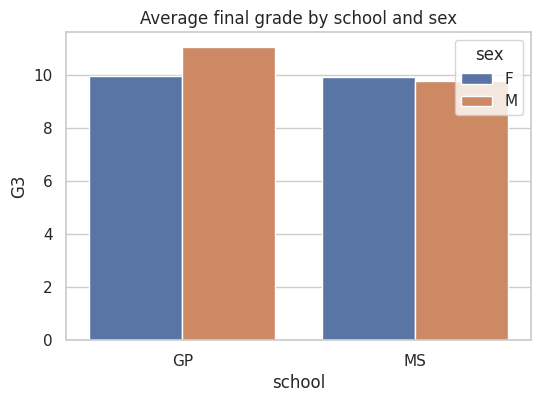

In [6]:
# Cell 5: average grade by two categories at once
plt.figure(figsize=(6, 4))
sns.barplot(x="school", y="G3", hue="sex", data=df, errorbar=None)
plt.title("Average final grade by school and sex")
plt.show()

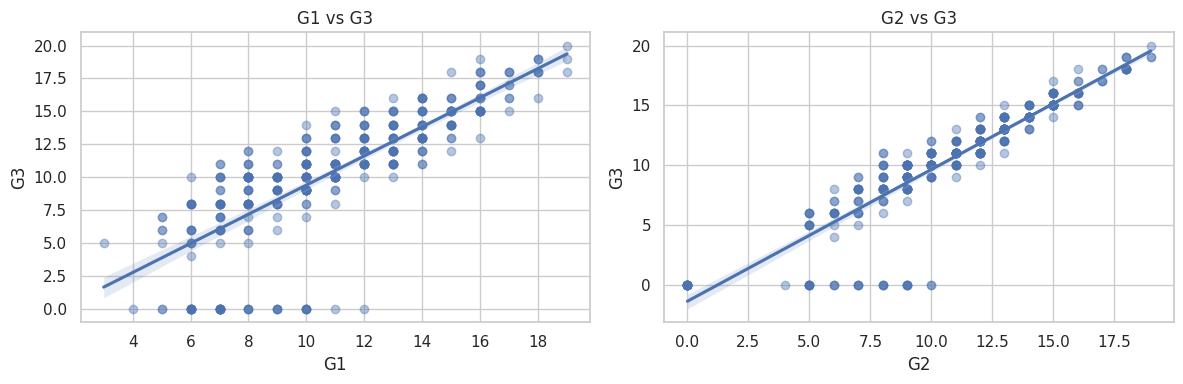

In [7]:
# Cell 6: scatter plots with a trend line
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(x="G1", y="G3", data=df, ax=axes[0], scatter_kws={"alpha": 0.4})
sns.regplot(x="G2", y="G3", data=df, ax=axes[1], scatter_kws={"alpha": 0.4})
axes[0].set_title("G1 vs G3")
axes[1].set_title("G2 vs G3")
plt.tight_layout()
plt.show()

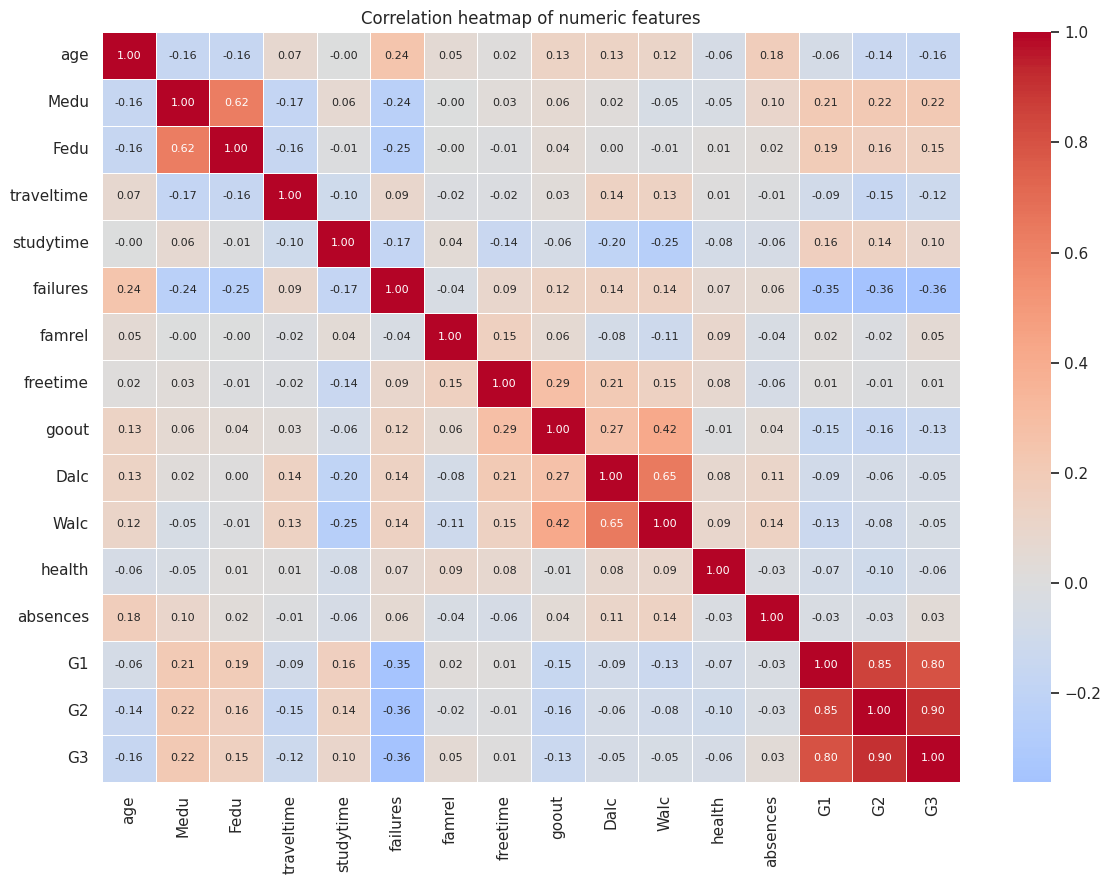

In [8]:
# Cell 7: the correlation heatmap
num = df.select_dtypes(include="number")
corr = num.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"size": 8}, linewidths=0.5)
plt.title("Correlation heatmap of numeric features")
plt.tight_layout()
plt.savefig("heatmap.png", dpi=150, bbox_inches="tight")   # saved for your report
plt.show()

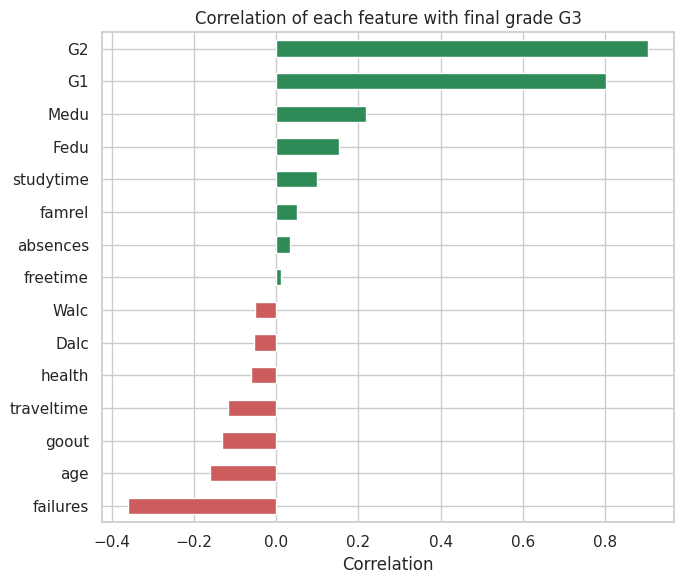

G2            0.90
G1            0.80
Medu          0.22
Fedu          0.15
studytime     0.10
famrel        0.05
absences      0.03
freetime      0.01
Walc         -0.05
Dalc         -0.05
health       -0.06
traveltime   -0.12
goout        -0.13
age          -0.16
failures     -0.36
Name: G3, dtype: float64


In [9]:
# Cell 8: which features correlate most with G3?
g3_corr = corr["G3"].drop("G3").sort_values()

plt.figure(figsize=(7, 6))
g3_corr.plot(kind="barh", color=np.where(g3_corr > 0, "seagreen", "indianred"))
plt.title("Correlation of each feature with final grade G3")
plt.xlabel("Correlation")
plt.tight_layout()
plt.savefig("g3_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

print(g3_corr.sort_values(ascending=False).round(2))

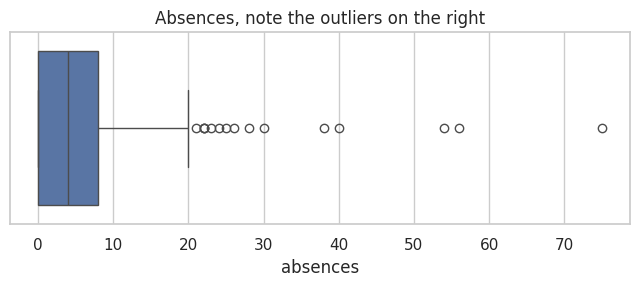

Students with G3 = 0: 38
Their average G2: 4.657894736842105
Their average absences: 0.0
Average absences of everyone else: 6.3165266106442575


In [10]:
# Cell 9: outliers and zero grades
plt.figure(figsize=(8, 2.5))
sns.boxplot(x=df["absences"])
plt.title("Absences, note the outliers on the right")
plt.show()

zeros = df[df["G3"] == 0]
print("Students with G3 = 0:", len(zeros))
print("Their average G2:", zeros["G2"].mean())
print("Their average absences:", zeros["absences"].mean())
print("Average absences of everyone else:", df[df["G3"] > 0]["absences"].mean())